# Mamíferos de Colombia — Ensamble, ubicación, regularización L1/L2, destilación y modelo para celular

| Sección | Tema del curso | Resultado |
|---|---|---|
| 0–3 | Ingesta, auditoría, división por registro GBIF, *Data Augmentation* | misma división del entrenamiento (verificada) |
| 7.1–7.5 | **Ensamble de modelos** (2× EfficientNetV2-S) | 93,7 % en prueba (solo imagen) |
| 7.6 | **Ensamble + ubicación** de la cámara trampa | 95,3 % validación · 95,4 % prueba |
| 8 | **Regularización L1 vs. L2** (defensa técnica) | comparación controlada |
| 9 | **Destilación de conocimiento** → estudiante **MobileNetV3-Large** | modelo liviano |
| 10 | **Preparación para móviles**: TensorFlow Lite (tamaño, latencia, conversión) | .tflite float32 / float16 / int8 |
| 11 | **Ensamble vs. modelo destilado** + archivos para la app | tabla final |

**Reglas para que el resultado sea honesto:** misma división del entrenamiento (verificada archivo por archivo); toda elección (pesos, TTA, ubicación, temperatura) se hace con **validación**; la **prueba** (fotos de Colombia nunca vistas) se usa al final.
**Entradas:** `mamiferos-colombia-40` + los dos modelos EfficientNetV2-S entrenados. **Ejecución:** GPU T4 · *Save Version → Save & Run All*.

---
# 0–3. Misma configuración, ingesta, auditoría, división y lectura que el entrenamiento

In [1]:
# 0.1 CONFIGURACIÓN (todas las decisiones del modelo están aquí)
import os, sys, io, json, time, math, random, shutil, zipfile, hashlib, logging, warnings
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
warnings.filterwarnings("ignore")

EN_KAGGLE = Path("/kaggle/input").exists()

# ---------- Datos ----------
FRAC_VAL, FRAC_TEST = 0.15, 0.15       # validación y prueba: SOLO fotos de Colombia, separadas por registro (gbifID)
MAX_TRAIN_POR_CLASE = 1200             # tope en entrenamiento para que la ardilla colirroja (2.452) no domine

# ---------- Modelo profesor (Transfer Learning) ----------
MODELO_BASE = "EfficientNetV2S"
IMG_SIZE = 260
BATCH = 32
DENSA = 512                            # neuronas de la capa densa antes de la salida
DROPOUT_1, DROPOUT_2 = 0.40, 0.30      # anti-overfitting
REGULARIZACION, FACTOR_REG = "l2", 1e-4   # "l1", "l2", "l1_l2" o None  (penaliza los pesos grandes)
LABEL_SMOOTHING = 0.10

# ---------- Entrenamiento ----------
EPOCAS_ETAPA1 = 10                     # etapa 1: base congelada, solo se entrena la cabeza
EPOCAS_TOTALES = 60                    # etapa 2: ajuste fino de la parte alta de la base (épocas 11 a 60 = 50 épocas)
LR_ETAPA1, LR_ETAPA2 = 1e-3, 1e-4      # optimizador Adam
FRACCION_AJUSTE_FINO = 0.60            # se descongela el 60 % final de las capas de la base
PACIENCIA = 12                         # EarlyStopping: para si val_accuracy no mejora en 12 épocas
EPOCA_MINIMA = 50                      # EarlyStopping no puede detener el entrenamiento antes de la época 50
META_ACCURACY = 0.94

MODO_PRUEBA = False                    # True = corrida corta de demostración (pocos lotes, 2 épocas) para verificar el pipeline
SEED = 42
random.seed(SEED); np.random.seed(SEED)

print("Kaggle:", EN_KAGGLE, "| modelo:", MODELO_BASE, f"{IMG_SIZE}px | épocas: {EPOCAS_ETAPA1} + {EPOCAS_TOTALES - EPOCAS_ETAPA1} = {EPOCAS_TOTALES}",
      "| MODO_PRUEBA" if MODO_PRUEBA else "")

Kaggle: True | modelo: EfficientNetV2S 260px | épocas: 10 + 50 = 60 


In [2]:
# 0.2 Entorno: GPU, TensorFlow/Keras, carpetas de salida y LOG
import tensorflow as tf
import keras
from keras import layers, regularizers
from IPython.display import display

BASE_SALIDA = Path("/kaggle/working") if EN_KAGGLE else Path.cwd()
SALIDA = BASE_SALIDA / "ensamble"   # la prueba no mezcla sus archivos con los reales
EVI = SALIDA / "evidencia"
for p in [SALIDA, EVI, SALIDA / "logs"]:
    p.mkdir(parents=True, exist_ok=True)

log = logging.getLogger("ENTRENAMIENTO"); log.setLevel(logging.INFO); log.handlers.clear(); log.propagate = False
_fmt = logging.Formatter("%(asctime)s | %(levelname)-7s | %(message)s", "%Y-%m-%d %H:%M:%S")
_fh = logging.FileHandler(SALIDA / "logs" / f"entrenamiento_{datetime.now():%Y%m%d_%H%M%S}.log", encoding="utf-8")
_sh = logging.StreamHandler(sys.stdout)
for h in (_fh, _sh):
    h.setFormatter(_fmt); log.addHandler(h)

GPUS = tf.config.list_physical_devices("GPU")
if GPUS:
    keras.mixed_precision.set_global_policy("mixed_float16")     # ~2x más rápido en GPU T4
keras.utils.set_random_seed(SEED)
log.info("=" * 70)
log.info(f"SESIÓN DE ENTRENAMIENTO | TensorFlow {tf.__version__} | Keras {keras.__version__} | "
         f"GPU: {[g.name for g in GPUS] or 'NINGUNA'} | precisión: {keras.mixed_precision.global_policy().name}")
log.info(f"Salidas en: {SALIDA}")
if not GPUS:
    print("⚠️  No hay GPU. Panel derecho → Session options → Accelerator: GPU T4 x2 (requiere celular verificado).")

2026-10-23 23:48:15 | INFO    | ======================================================================
2026-10-23 23:48:15 | INFO    | SESIÓN DE ENTRENAMIENTO | TensorFlow 2.20.0 | Keras 3.13.2 | GPU: ['/physical_device:GPU:0', '/physical_device:GPU:1'] | precisión: mixed_float16
2026-10-23 23:48:15 | INFO    | Salidas en: /kaggle/working/ensamble


In [3]:
# 1.1 Ingesta: ubicar el dataset subido a Kaggle (Kaggle descomprime el ZIP solo) y leer metadata.csv
RAIZ = Path("/kaggle/input") if EN_KAGGLE else Path.cwd()
encontrados = sorted(RAIZ.rglob("metadata.csv"))
if encontrados:
    DATOS = encontrados[0].parent
else:                                                  # por si el ZIP no se descomprimió
    zips = sorted(RAIZ.rglob("*.zip"))
    assert zips, "No encuentro el dataset. Panel derecho → Input → Add Input → Your Datasets → mamiferos-colombia-40"
    DATOS = Path("/tmp/datos")
    with zipfile.ZipFile(zips[0]) as z:
        z.extractall(DATOS)
meta = pd.read_csv(DATOS / "metadata.csv")
carpeta_img = DATOS / "dataset" if (DATOS / "dataset").exists() else DATOS
meta["ruta"] = meta["archivo"].map(lambda a: str(carpeta_img / a))
log.info(f"Dataset en: {DATOS}")
log.info(f"INGESTA: {len(meta)} imágenes | {meta.clase.nunique()} clases | "
         f"Colombia {int((meta.origen == 'colombia').sum())} | Latinoamérica {int((meta.origen != 'colombia').sum())}")

2026-10-23 23:48:36 | INFO    | Dataset en: /kaggle/input/datasets/davida29/mamiferos-colombia-40
2026-10-23 23:48:36 | INFO    | INGESTA: 23374 imágenes | 40 clases | Colombia 16147 | Latinoamérica 7227


In [4]:
# 1.2 Auditoría automática de la ingesta (limpieza antes de entrenar)
def auditar(ruta):
    p = Path(ruta)
    if not p.exists():
        return "no_existe", ""
    data = p.read_bytes()
    try:
        with Image.open(io.BytesIO(data)) as im:
            im.verify()
        with Image.open(io.BytesIO(data)) as im:
            w, h = im.size
    except Exception:
        return "corrupta", ""
    if min(w, h) < 64:
        return "muy_pequena", ""
    return "", hashlib.sha256(data).hexdigest()

t0 = time.time()
res = [auditar(r) for r in meta["ruta"]]
meta["problema"] = [r[0] for r in res]; meta["sha256"] = [r[1] for r in res]
dup = meta["sha256"].ne("") & meta.duplicated("sha256", keep="first")
meta.loc[dup, "problema"] = "duplicado_exacto"
aud = meta["problema"].replace("", "OK").value_counts()
log.info(f"AUDITORÍA ({time.time() - t0:.0f} s): " + " | ".join(f"{k}={v}" for k, v in aud.items()))
display(aud.to_frame("imágenes"))
meta = meta[meta["problema"] == ""].reset_index(drop=True)

CLASES = sorted(meta["clase"].unique())
N_CLASES = len(CLASES)
IDX = {c: i for i, c in enumerate(CLASES)}
meta["y"] = meta["clase"].map(IDX)
NOMBRE = meta.drop_duplicates("clase").set_index("clase")["nombre_comun"].to_dict()
log.info(f"Imágenes válidas para entrenar: {len(meta)} | clases: {N_CLASES}")

2026-10-23 23:49:50 | INFO    | AUDITORÍA (75 s): OK=23358 | muy_pequena=16


,imágenes
problema,
OK,23358
muy_pequena,16


2026-10-23 23:49:50 | INFO    | Imágenes válidas para entrenar: 23358 | clases: 40


In [5]:
# 2.1 División estratificada por clase y agrupada por registro GBIF
rng = np.random.default_rng(SEED)
meta["split"] = "train"
for c, d in meta.groupby("clase"):
    reg_fuera = set(d.loc[d["origen"] != "colombia", "gbifID"])     # registros de otros países: solo entrenamiento
    col = d[~d["gbifID"].isin(reg_fuera)]
    por_reg = col.groupby("gbifID").size()
    ids = por_reg.index.to_numpy().copy(); rng.shuffle(ids)
    total, acum, asign = int(por_reg.sum()), 0, {}
    for g in ids:
        asign[g] = "test" if acum < total * FRAC_TEST else ("val" if acum < total * (FRAC_TEST + FRAC_VAL) else "train")
        acum += int(por_reg[g])
    meta.loc[col.index, "split"] = col["gbifID"].map(asign).values

# Tope por clase en entrenamiento (se priorizan las fotos de Colombia)
meta["_azar"] = rng.random(len(meta))
tr = meta[meta.split == "train"].sort_values(["clase", "origen", "_azar"],
                                             key=lambda s: (s != "colombia") if s.name == "origen" else s)
sobran = tr.groupby("clase").cumcount() >= MAX_TRAIN_POR_CLASE
meta.loc[tr.index[sobran.values], "split"] = "sin_usar"

# Verificación: ningún registro GBIF puede estar en dos grupos
g = {s: set(meta.loc[meta.split == s, "gbifID"]) for s in ["train", "val", "test"]}
assert not (g["train"] & g["val"]) and not (g["train"] & g["test"]) and not (g["val"] & g["test"]), "¡Fuga de datos!"
assert (meta.loc[meta.split.isin(["val", "test"]), "origen"] == "colombia").all()

tabla_split = pd.crosstab(meta["clase"], meta["split"]).reindex(columns=["train", "val", "test", "sin_usar"], fill_value=0)
display(tabla_split)
tabla_split.to_csv(EVI / "division_por_clase.csv", encoding="utf-8-sig")
meta.drop(columns=["_azar"]).to_csv(SALIDA / "division_dataset.csv", index=False, encoding="utf-8-sig")
cuenta = meta["split"].value_counts()
log.info("DIVISIÓN por gbifID (sin fuga de datos ✓): " + " | ".join(f"{k}={cuenta.get(k, 0)}" for k in ["train", "val", "test", "sin_usar"]))

split,train,val,test,sin_usar
clase,,,,
ardilla_andina,156,34,34,0
ardilla_colirroja,1200,366,370,516
armadillo,637,14,14,0
armadillo_coletrapo,145,9,12,0
capuchino_cariblanco,459,20,20,0
capuchino_santa_marta,263,57,58,0
chiguiro,271,58,59,0
chucha_comun,462,99,100,0
curi,292,63,63,0


2026-10-23 23:49:51 | INFO    | DIVISIÓN por gbifID (sin fuga de datos ✓): train=17960 | val=2424 | test=2458 | sin_usar=516


In [6]:
# 2.2 Pesos por clase (compensan el desbalance): peso = N / (K · n_clase), limitado entre 0.5 y 5
n_tr = meta[meta.split == "train"].groupby("y").size().reindex(range(N_CLASES), fill_value=1)
PESOS = np.clip(n_tr.sum() / (N_CLASES * n_tr), 0.5, 5.0)
meta["peso"] = meta["y"].map(PESOS)
display(pd.DataFrame({"clase": CLASES, "imagenes_train": n_tr.values, "peso": PESOS.round(2).values})
          .sort_values("peso", ascending=False).head(10))
log.info(f"Pesos por clase: mínimo {PESOS.min():.2f} ({CLASES[int(PESOS.idxmin())]}) | "
         f"máximo {PESOS.max():.2f} ({CLASES[int(PESOS.idxmax())]})")

,clase,imagenes_train,peso
14,mico_cariblanco,111,4.05
3,armadillo_coletrapo,145,3.10
0,ardilla_andina,156,2.88
11,guagua_lapa,219,2.05
38,zaino,231,1.94
33,tamandua_sureno,231,1.94
35,titi_gris,251,1.79
23,ocelote,251,1.79
32,tamandua,263,1.71
5,capuchino_santa_marta,263,1.71


2026-10-23 23:49:51 | INFO    | Pesos por clase: mínimo 0.50 (ardilla_colirroja) | máximo 4.05 (mico_cariblanco)


In [7]:
# 3.1 Lectura eficiente con tf.data (paralela + prefetch)
AUTOTUNE = tf.data.AUTOTUNE

def leer_imagen(ruta, size):
    img = tf.io.decode_jpeg(tf.io.read_file(ruta), channels=3)
    return tf.image.resize(img, (size, size), antialias=True)          # float32 en 0..255

def hacer_ds(df, size=IMG_SIZE, entrenamiento=False):
    if entrenamiento:
        ds = tf.data.Dataset.from_tensor_slices((df["ruta"].values, df["y"].values.astype("int32"),
                                                 df["peso"].values.astype("float32")))
        ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)
        ds = ds.map(lambda r, y, w: (leer_imagen(r, size), tf.one_hot(y, N_CLASES), w), num_parallel_calls=AUTOTUNE)
    else:
        ds = tf.data.Dataset.from_tensor_slices((df["ruta"].values, df["y"].values.astype("int32")))
        ds = ds.map(lambda r, y: (leer_imagen(r, size), tf.one_hot(y, N_CLASES)), num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

TRAIN = meta[meta.split == "train"].reset_index(drop=True)
VAL = meta[meta.split == "val"].reset_index(drop=True)
TEST = meta[meta.split == "test"].reset_index(drop=True)
ds_train, ds_val, ds_test = hacer_ds(TRAIN, entrenamiento=True), hacer_ds(VAL), hacer_ds(TEST)
if MODO_PRUEBA:
    ds_train, ds_val, ds_test = ds_train.take(15), ds_val.take(5), ds_test.take(5)
log.info(f"tf.data listo | train {len(TRAIN)} | val {len(VAL)} | test {len(TEST)} | lote {BATCH} | "
         f"{math.ceil(len(TRAIN) / BATCH)} pasos por época")

I0000 00:00:1792799391.977025      24 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792799391.980364      24 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


2026-10-23 23:49:53 | INFO    | tf.data listo | train 17960 | val 2424 | test 2458 | lote 32 | 562 pasos por época


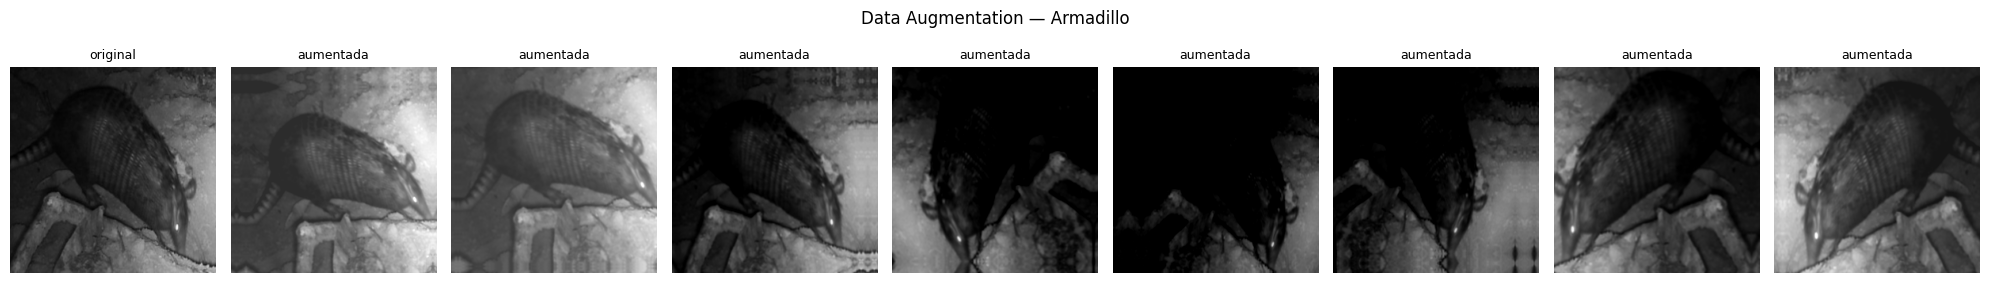

In [8]:
# 3.2 Capas de Data Augmentation (incluye una capa propia: escala de grises aleatoria)
class GrisAleatorio(layers.Layer):
    """Convierte a escala de grises una fracción p de las imágenes (simula fotos infrarrojas nocturnas)."""
    def __init__(self, p=0.2, **kwargs):
        super().__init__(**kwargs)
        self.p = p
    def call(self, x, training=None):
        if not training:
            return x
        gris = x[..., 0:1] * 0.299 + x[..., 1:2] * 0.587 + x[..., 2:3] * 0.114
        gris = tf.concat([gris, gris, gris], axis=-1)
        m = tf.cast(tf.random.uniform([tf.shape(x)[0], 1, 1, 1]) < self.p, x.dtype)
        return m * gris + (1 - m) * x
    def get_config(self):
        return {**super().get_config(), "p": self.p}

def crear_aumento():
    f32 = dict(dtype="float32")
    return keras.Sequential([
        layers.RandomFlip("horizontal", **f32),
        layers.RandomRotation(0.08, fill_mode="reflect", **f32),
        layers.RandomZoom((-0.15, 0.15), fill_mode="reflect", **f32),
        layers.RandomTranslation(0.08, 0.08, fill_mode="reflect", **f32),
        layers.RandomContrast(0.25, **f32),
        layers.RandomBrightness(0.25, **f32),
        GrisAleatorio(0.20, **f32),
    ], name="aumento_de_datos")

# Ejemplo: la misma imagen con 8 aumentos distintos
aum = crear_aumento()
ej = leer_imagen(TRAIN["ruta"].iloc[0], IMG_SIZE)[None]
fig, axs = plt.subplots(1, 9, figsize=(20, 3))
axs[0].imshow(ej[0].numpy().astype("uint8")); axs[0].set_title("original", fontsize=9)
for ax in axs[1:]:
    ax.imshow(np.clip(aum(ej, training=True)[0].numpy(), 0, 255).astype("uint8")); ax.set_title("aumentada", fontsize=9)
for ax in axs: ax.axis("off")
plt.suptitle(f"Data Augmentation — {NOMBRE[TRAIN['clase'].iloc[0]]}"); plt.tight_layout()
plt.savefig(EVI / "data_augmentation_ejemplos.png", dpi=100); plt.show()

---
# 7. Ensamble

In [9]:
# 7.1 Cargar los modelos entrenados y verificar que la división de prueba sea idéntica
archivos = sorted(Path("/kaggle/input").rglob("*.keras"))
por_carpeta = {}
for f in archivos:
    if "respaldo" in str(f):
        continue
    por_carpeta.setdefault(f.parent, []).append(f)
RUTAS_MODELOS = []
for carpeta, fs in por_carpeta.items():
    preferido = [f for f in fs if f.name == "profesor_mejor.keras"] or [f for f in fs if f.name == "profesor_final.keras"] or fs
    RUTAS_MODELOS.append(preferido[0])
assert len(RUTAS_MODELOS) >= 2, f"Se necesitan al menos 2 modelos y encontré {len(RUTAS_MODELOS)}: {archivos}"

def nombre_modelo(ruta):
    partes = [p for p in ruta.parts if p not in ("kaggle", "input", "/", "entrenamiento", ruta.name)]
    return "/".join(partes[-2:]) if partes else ruta.stem

MODELOS = {}
for r in RUTAS_MODELOS:
    MODELOS[nombre_modelo(r)] = keras.models.load_model(r, custom_objects={"GrisAleatorio": GrisAleatorio})
    log.info(f"Modelo cargado: {nombre_modelo(r)}  ({r}, {r.stat().st_size / 1e6:.0f} MB)")

# La división se toma EXACTAMENTE de la que usaron los modelos al entrenar (division_dataset.csv de cada modelo).
# Así no depende de versiones de librerías de Kaggle: es la misma división, archivo por archivo.
divs = {f: pd.read_csv(f) for f in sorted(Path("/kaggle/input").rglob("division_dataset.csv"))}
assert divs, "No encontré division_dataset.csv en las entradas"
ref_f, ref = next(iter(divs.items()))
ref = ref.set_index("archivo")["split"]
for f, d in divs.items():
    s = d.set_index("archivo")["split"]
    igual = all(set(s[s == g].index) == set(ref[ref == g].index) for g in ["val", "test"])
    log.info(f"División de {f.parts[-3]}: {'✓ igual' if igual else '✗ DIFERENTE'} a la de {ref_f.parts[-3]}")
    assert igual, "Los modelos de entrada no se entrenaron con la misma división"
meta["split"] = meta["archivo"].map(ref).fillna("sin_usar")
n_tr = meta[meta.split == "train"].groupby("y").size().reindex(range(N_CLASES), fill_value=1)
PESOS = np.clip(n_tr.sum() / (N_CLASES * n_tr), 0.5, 5.0)
meta["peso"] = meta["y"].map(PESOS)
TRAIN = meta[meta.split == "train"].reset_index(drop=True)
VAL = meta[meta.split == "val"].reset_index(drop=True)
TEST = meta[meta.split == "test"].reset_index(drop=True)
ds_train, ds_val, ds_test = hacer_ds(TRAIN, entrenamiento=True), hacer_ds(VAL), hacer_ds(TEST)
log.info(f"Se usa la división EXACTA del entrenamiento: train {len(TRAIN)} | val {len(VAL)} | test {len(TEST)}")

2026-10-23 23:50:15 | INFO    | Modelo cargado: davida29/modelo-mamiferos-v2  (/kaggle/input/datasets/davida29/modelo-mamiferos-v2/entrenamiento/profesor_mejor.keras, 262 MB)
2026-10-23 23:50:25 | INFO    | Modelo cargado: davida29/notebook5bd9742cb0  (/kaggle/input/notebooks/davida29/notebook5bd9742cb0/entrenamiento/profesor_mejor.keras, 369 MB)
2026-10-23 23:50:35 | INFO    | División de modelo-mamiferos-v2: ✓ igual a la de modelo-mamiferos-v2
2026-10-23 23:50:35 | INFO    | División de notebook5bd9742cb0: ✓ igual a la de modelo-mamiferos-v2
2026-10-23 23:50:35 | INFO    | Se usa la división EXACTA del entrenamiento: train 17960 | val 2424 | test 2458


In [10]:
# 7.2 Probabilidades de cada modelo en validación y prueba (foto original y volteada)
def probas(modelo, ds, volteo=False):
    size = modelo.input_shape[1]                      # cada modelo recibe las fotos a su propio tamaño
    if size != IMG_SIZE:
        ds = ds.map(lambda x, y: (tf.image.resize(x, (size, size), antialias=True), y))
    if volteo:
        ds = ds.map(lambda x, y: (tf.image.flip_left_right(x), y))
    return tf.nn.softmax(modelo.predict(ds, verbose=0)).numpy()

P = {}
for nombre, m in MODELOS.items():
    t0 = time.time()
    for grupo, ds in [("val", ds_val), ("test", ds_test)]:
        P[(nombre, grupo, "orig")] = probas(m, ds)
        P[(nombre, grupo, "flip")] = probas(m, ds, volteo=True)
    log.info(f"Predicciones de {nombre} listas ({time.time() - t0:.0f} s)")
Y = {"val": VAL["y"].values, "test": TEST["y"].values}
acc = lambda p, g: float((p.argmax(1) == Y[g]).mean())

2026-10-23 23:51:51 | INFO    | Predicciones de davida29/modelo-mamiferos-v2 listas (76 s)
2026-10-23 23:52:47 | INFO    | Predicciones de davida29/notebook5bd9742cb0 listas (56 s)


In [11]:
# 7.3 Elegir la mejor combinación USANDO SOLO VALIDACIÓN
nombres = list(MODELOS)
def combinar(pesos, grupo, tta):
    p = 0
    for w, n in zip(pesos, nombres):
        pn = P[(n, grupo, "orig")]
        if tta:
            pn = (pn + P[(n, grupo, "flip")]) / 2
        p = p + w * pn
    return p / sum(pesos)

opciones = []
for tta in (False, True):
    for i, n in enumerate(nombres):                                  # cada modelo solo
        w = [0] * len(nombres); w[i] = 1
        opciones.append((f"{n}" + (" + TTA" if tta else ""), tuple(w), tta))
    if len(nombres) == 2:                                            # ensamble con distintos pesos
        for a in np.round(np.arange(0.1, 1.0, 0.1), 1):
            opciones.append((f"ensamble {a:.1f}/{1 - a:.1f}" + (" + TTA" if tta else ""), (a, round(1 - a, 1)), tta))
    else:
        opciones.append(("ensamble pesos iguales" + (" + TTA" if tta else ""), tuple([1] * len(nombres)), tta))

tabla = pd.DataFrame([{"opción": o, "val_accuracy": acc(combinar(w, "val", t), "val")} for o, w, t in opciones])
tabla = tabla.sort_values("val_accuracy", ascending=False).reset_index(drop=True)
display(tabla.head(12).round(4))
mejor_op = tabla.iloc[0]["opción"]
_, PESOS_ENS, TTA_ENS = next(o for o in opciones if o[0] == mejor_op)
log.info(f"ELEGIDO CON VALIDACIÓN: {mejor_op} | val_accuracy {tabla.iloc[0]['val_accuracy']:.4f}")

,opción,val_accuracy
0,ensamble 0.4/0.6 + TTA,0.9278
1,ensamble 0.5/0.5 + TTA,0.9274
2,ensamble 0.3/0.7 + TTA,0.9270
3,ensamble 0.6/0.4 + TTA,0.9270
4,ensamble 0.4/0.6,0.9266
5,ensamble 0.5/0.5,0.9266
6,ensamble 0.2/0.8 + TTA,0.9266
7,ensamble 0.7/0.3 + TTA,0.9262
8,ensamble 0.7/0.3,0.9257
9,ensamble 0.6/0.4,0.9257


2026-10-23 23:52:47 | INFO    | ELEGIDO CON VALIDACIÓN: ensamble 0.4/0.6 + TTA | val_accuracy 0.9278


,modelo,test_accuracy
0,davida29/modelo-mamiferos-v2,0.9276
1,davida29/notebook5bd9742cb0,0.9317
2,ENSAMBLE: ensamble 0.4/0.6 + TTA,0.9373


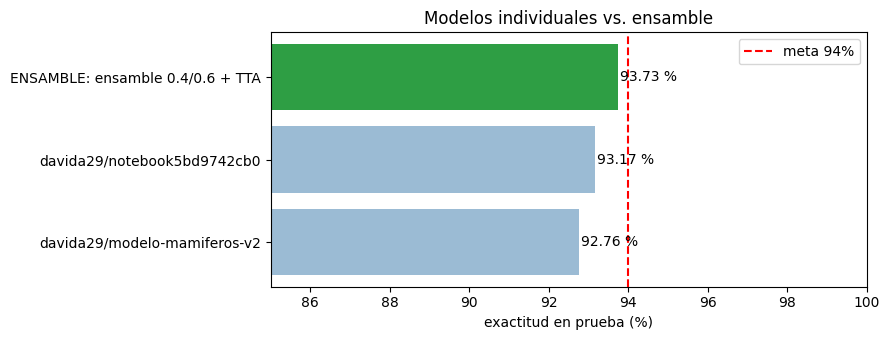

2026-10-23 23:52:47 | INFO    | ======================================================================
2026-10-23 23:52:47 | INFO    | ENSAMBLE — PRUEBA (2458 fotos de Colombia nunca vistas): accuracy 0.9373 | top-3 0.9849 | F1 macro 0.9200
2026-10-23 23:52:47 | INFO    | ❌ NO CUMPLE TODAVÍA la meta de 94%


In [12]:
# 7.4 Evaluación FINAL en PRUEBA (una sola vez) + comparación con cada modelo individual
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support

prob = combinar(PESOS_ENS, "test", TTA_ENS)
y_true, y_pred = Y["test"], prob.argmax(1)
acc_test = accuracy_score(y_true, y_pred)
top3 = float(np.mean([t in np.argsort(p)[-3:] for t, p in zip(y_true, prob)]))
_, _, f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=range(N_CLASES), average="macro", zero_division=0)

comparacion = pd.DataFrame(
    [{"modelo": n, "test_accuracy": acc(P[(n, "test", "orig")], "test")} for n in nombres] +
    [{"modelo": "ENSAMBLE: " + mejor_op, "test_accuracy": acc_test}]).round(4)
display(comparacion)
comparacion.to_csv(EVI / "comparacion_modelos_vs_ensamble.csv", index=False, encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.barh(comparacion["modelo"], comparacion["test_accuracy"] * 100,
        color=["#9bbbd4"] * len(nombres) + ["#2e9e44"])
ax.axvline(META_ACCURACY * 100, ls="--", c="red", label=f"meta {META_ACCURACY:.0%}")
for i, v in enumerate(comparacion["test_accuracy"] * 100):
    ax.text(v + 0.05, i, f"{v:.2f} %", va="center")
ax.set_xlim(85, 100); ax.set_xlabel("exactitud en prueba (%)"); ax.legend(); ax.set_title("Modelos individuales vs. ensamble")
plt.tight_layout(); plt.savefig(EVI / "ensamble_comparacion.png", dpi=110); plt.show()

log.info("=" * 70)
log.info(f"ENSAMBLE — PRUEBA ({len(y_true)} fotos de Colombia nunca vistas): accuracy {acc_test:.4f} | top-3 {top3:.4f} | F1 macro {f1:.4f}")
log.info(("✅ CUMPLE" if acc_test >= META_ACCURACY else "❌ NO CUMPLE TODAVÍA") + f" la meta de {META_ACCURACY:.0%}")

,nombre,precision,recall,f1-score,support
neque_negro,Ñeque negro,0.548,0.515,0.531,33.0
mono_ardilla_ecuatoriano,Mono ardilla ecuatoriano,0.767,0.805,0.786,41.0
mapache_cangrejero,Mapache cangrejero,0.793,0.852,0.821,27.0
armadillo_coletrapo,Armadillo coletrapo,0.833,0.833,0.833,12.0
mono_ardilla,Mono ardilla,0.845,0.845,0.845,58.0
tamandua_sureno,Tamandúa sureño,0.875,0.840,0.857,50.0
zaino,Zaino,0.878,0.843,0.860,51.0
danta,Danta,0.756,1.000,0.861,31.0
neque,Ñeque,0.879,0.885,0.882,139.0
tamandua,Tamandúa,0.941,0.842,0.889,57.0


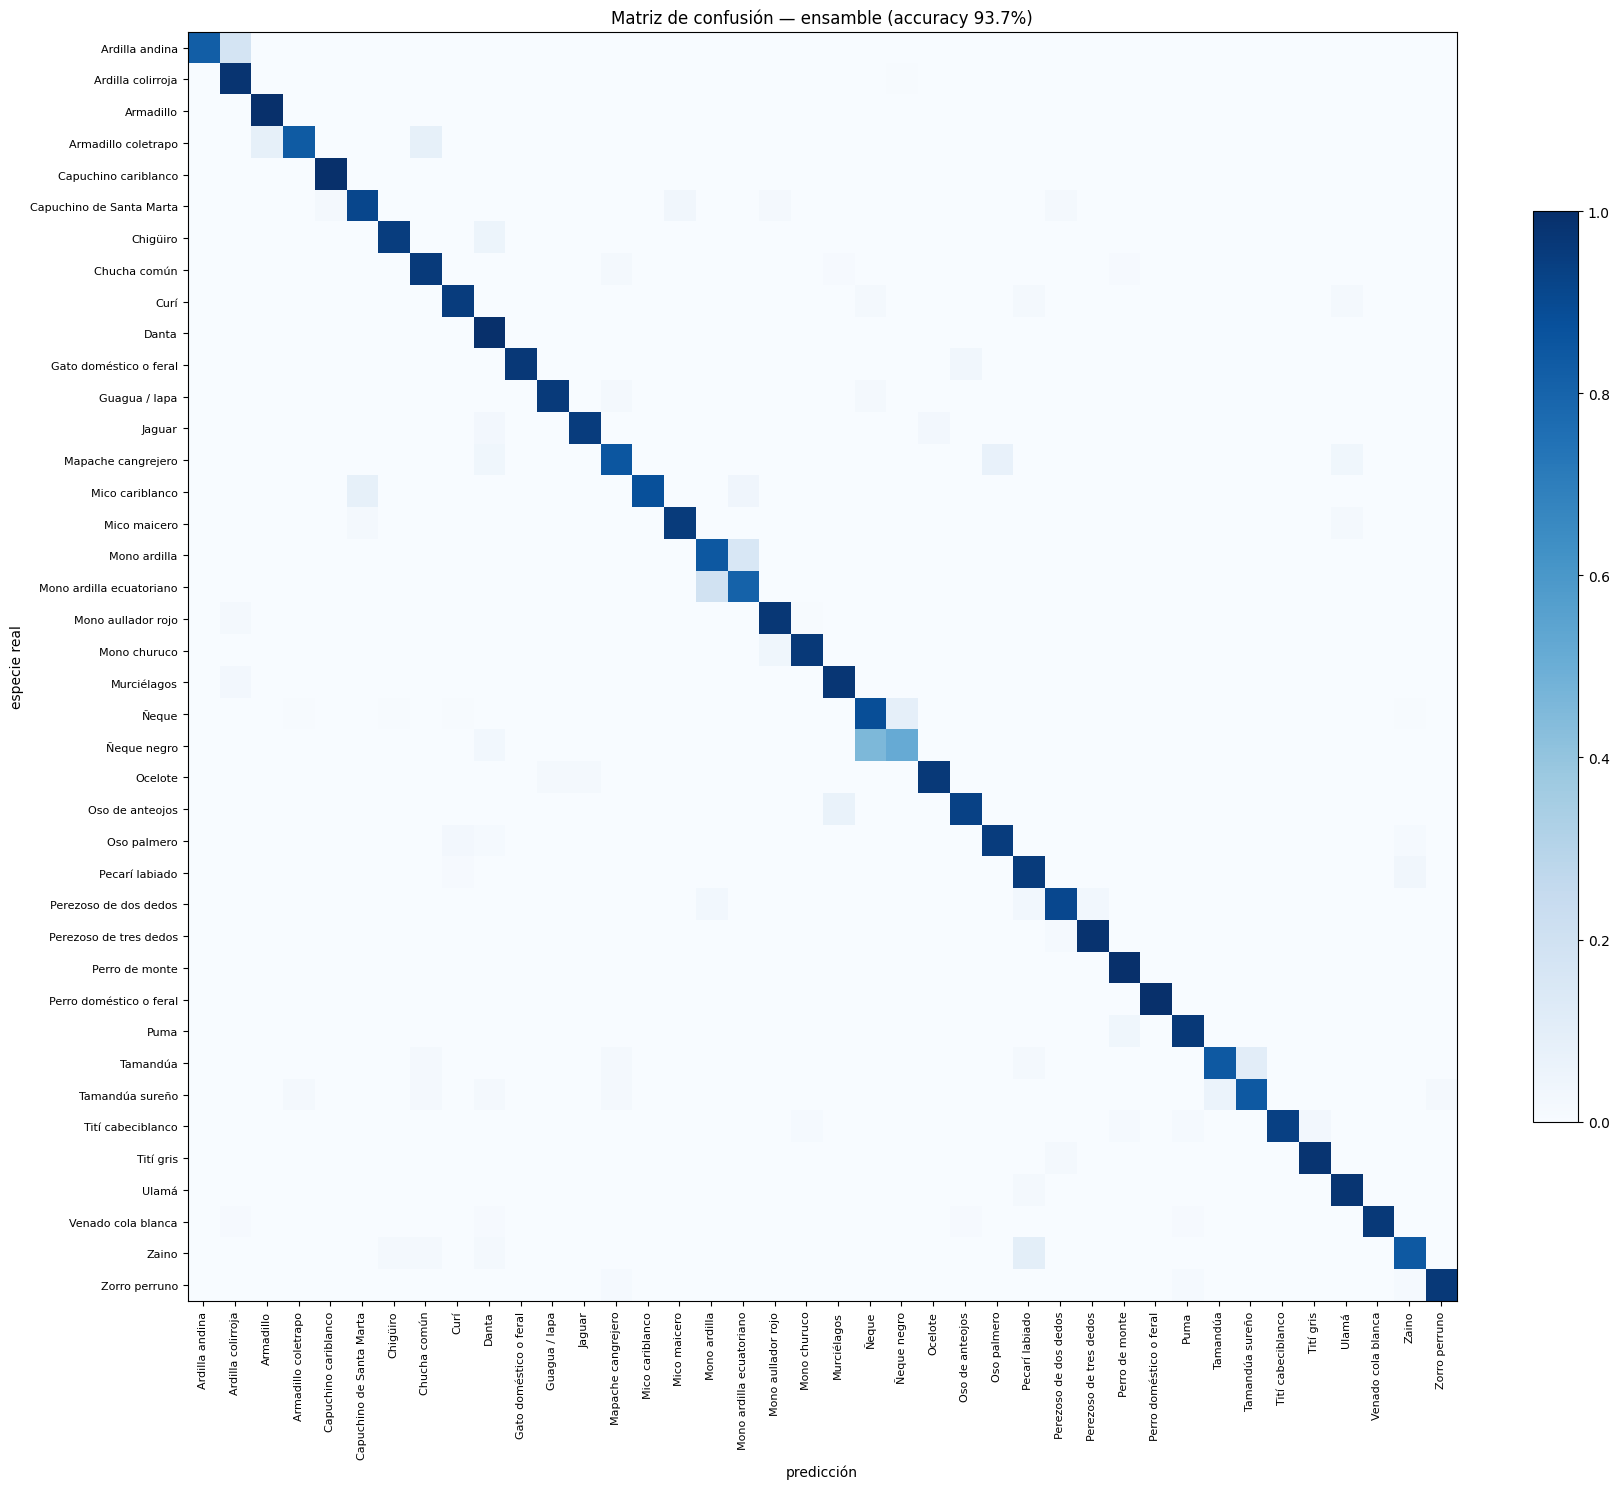

,errores,especie real,confundida con
0,15,Ñeque negro,Ñeque
1,12,Ñeque,Ñeque negro
2,9,Mono ardilla,Mono ardilla ecuatoriano
3,8,Mono ardilla ecuatoriano,Mono ardilla
4,6,Tamandúa,Tamandúa sureño
5,6,Ardilla andina,Ardilla colirroja
6,5,Zaino,Pecarí labiado
7,3,Tamandúa sureño,Tamandúa
8,3,Pecarí labiado,Zaino
9,3,Mono aullador rojo,Ardilla colirroja


,valor
fecha,2026-10-23T23:52:49
modelos,"[davida29/modelo-mamiferos-v2, davida29/notebo..."
combinacion_elegida_con_validacion,ensamble 0.4/0.6 + TTA
pesos,"[0.4, 0.6]"
tta,True
val_accuracy,0.9278
test_accuracy,0.9373
test_top3,0.9849
test_f1_macro,0.92
test_individuales,"{'davida29/modelo-mamiferos-v2': 0.9276, 'davi..."


In [13]:
# 7.5 Matriz de confusión y pares más confundidos del ensamble + resumen
rep = pd.DataFrame(classification_report(y_true, y_pred, labels=range(N_CLASES), target_names=CLASES,
                                         output_dict=True, zero_division=0)).T.iloc[:N_CLASES]
rep.insert(0, "nombre", [NOMBRE[c] for c in rep.index])
rep = rep.sort_values("f1-score"); display(rep.head(10).round(3))
rep.to_csv(EVI / "ensamble_reporte_por_clase.csv", encoding="utf-8-sig")

cm = confusion_matrix(y_true, y_pred, labels=range(N_CLASES))
cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(17, 15))
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(N_CLASES)); ax.set_yticks(range(N_CLASES))
ax.set_xticklabels([NOMBRE[c] for c in CLASES], rotation=90, fontsize=8)
ax.set_yticklabels([NOMBRE[c] for c in CLASES], fontsize=8)
ax.set_xlabel("predicción"); ax.set_ylabel("especie real")
ax.set_title(f"Matriz de confusión — ensamble (accuracy {acc_test:.1%})"); plt.colorbar(im, fraction=0.03)
plt.tight_layout(); plt.savefig(EVI / "ensamble_matriz_confusion.png", dpi=110); plt.show()

pares = sorted([(int(cm[i, j]), NOMBRE[CLASES[i]], NOMBRE[CLASES[j]]) for i in range(N_CLASES) for j in range(N_CLASES)
                if i != j and cm[i, j] > 0], reverse=True)[:12]
conf = pd.DataFrame(pares, columns=["errores", "especie real", "confundida con"])
display(conf); conf.to_csv(EVI / "ensamble_pares_mas_confundidos.csv", index=False, encoding="utf-8-sig")

resumen = {"fecha": datetime.now().isoformat(timespec="seconds"), "modelos": nombres,
           "combinacion_elegida_con_validacion": mejor_op, "pesos": list(PESOS_ENS), "tta": bool(TTA_ENS),
           "val_accuracy": round(float(tabla.iloc[0]["val_accuracy"]), 4),
           "test_accuracy": round(float(acc_test), 4), "test_top3": round(top3, 4), "test_f1_macro": round(float(f1), 4),
           "test_individuales": {n: round(acc(P[(n, "test", "orig")], "test"), 4) for n in nombres},
           "meta": META_ACCURACY, "cumple_meta": bool(acc_test >= META_ACCURACY)}
json.dump(resumen, open(EVI / "resumen_ensamble.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
display(pd.Series(resumen).to_frame("valor"))

In [14]:
# 7.6 Ensamble + UBICACIÓN: las cámaras trampa saben en qué departamento están.
#     Especies hermanas (ñeque / ñeque negro, mono ardilla / ecuatoriano, tamandúa / sureño) viven en regiones distintas.
#     p(especie | foto, lugar) ∝ p(especie | foto) × [p(especie | departamento) / p(especie)] ^ λ
#     El conocimiento por departamento se calcula SOLO con ENTRENAMIENTO; α y λ se eligen con VALIDACIÓN.
import unicodedata
def norm_dep(s):
    def f(x):
        if not isinstance(x, str) or not x.strip():
            return "desconocido"
        x = "".join(c for c in unicodedata.normalize("NFD", x.lower()) if unicodedata.category(c) != "Mn")
        for q in ["departamento de ", "departamento del ", "depto. de ", "depto ", "departamento "]:
            x = x.replace(q, "")
        return x.strip()
    return s.map(f)

TRAIN_D, VAL_D, TEST_D = norm_dep(TRAIN["departamento"]), norm_dep(VAL["departamento"]), norm_dep(TEST["departamento"])
conteo = pd.crosstab(TRAIN_D, TRAIN["y"]).reindex(columns=range(N_CLASES), fill_value=0)
conteo = conteo.drop(index="desconocido", errors="ignore")
log.info(f"Ubicación: {len(conteo)} departamentos/provincias con registros de entrenamiento | "
         f"val con departamento conocido {int((VAL_D != 'desconocido').mean() * 100)} % | "
         f"prueba {int((TEST_D != 'desconocido').mean() * 100)} %")

def factor_lugar(deps, alpha):
    p_dep = (conteo + alpha).div(conteo.sum(1) + alpha * N_CLASES, axis=0)
    glob = conteo.sum(0) + alpha
    p_glob = glob / glob.sum()
    r = p_dep / p_glob
    return np.vstack([r.loc[d].values if d in r.index else np.ones(N_CLASES) for d in deps])

def con_lugar(p_img, deps, alpha, lam):
    p = p_img * factor_lugar(deps, alpha) ** lam
    return p / p.sum(1, keepdims=True)

p_val_img, p_test_img = combinar(PESOS_ENS, "val", TTA_ENS), combinar(PESOS_ENS, "test", TTA_ENS)
filas = []
for alpha in [1, 3, 10]:
    for lam in [0, 0.25, 0.5, 0.75, 1.0]:
        filas.append({"alpha": alpha, "lambda": lam, "val_accuracy": acc(con_lugar(p_val_img, VAL_D, alpha, lam), "val")})
grid = pd.DataFrame(filas).sort_values("val_accuracy", ascending=False, kind="mergesort").reset_index(drop=True)
display(grid.head(8).round(4))
A_LUG, L_LUG = grid.iloc[0]["alpha"], grid.iloc[0]["lambda"]
log.info(f"ELEGIDO CON VALIDACIÓN: alpha={A_LUG} lambda={L_LUG} | val_accuracy {grid.iloc[0]['val_accuracy']:.4f} "
         f"(sin ubicación {acc(p_val_img, 'val'):.4f})")

prob_l = con_lugar(p_test_img, TEST_D, A_LUG, L_LUG)
y_pred_l = prob_l.argmax(1)
acc_l = accuracy_score(Y["test"], y_pred_l)
top3_l = float(np.mean([t in np.argsort(p)[-3:] for t, p in zip(Y["test"], prob_l)]))
_, _, f1_l, _ = precision_recall_fscore_support(Y["test"], y_pred_l, labels=range(N_CLASES), average="macro", zero_division=0)
comp = pd.DataFrame([{"modelo": "Ensamble (solo imagen)", "val_accuracy": acc(p_val_img, "val"), "test_accuracy": acc(p_test_img, "test")},
                     {"modelo": "Ensamble + ubicación", "val_accuracy": grid.iloc[0]["val_accuracy"], "test_accuracy": acc_l}]).round(4)
display(comp); comp.to_csv(EVI / "ensamble_con_ubicacion.csv", index=False, encoding="utf-8-sig")
for c in ["neque_negro", "mono_ardilla_ecuatoriano", "tamandua_sureno", "armadillo_coletrapo"]:
    if c in IDX:
        m = Y["test"] == IDX[c]
        log.info(f"   {NOMBRE[c]:<28s} acierto solo imagen {np.mean(p_test_img[m].argmax(1) == IDX[c]):.2f} → con ubicación {np.mean(y_pred_l[m] == IDX[c]):.2f}")
log.info("=" * 70)
log.info(f"ENSAMBLE + UBICACIÓN — PRUEBA ({len(y_pred_l)} fotos de Colombia): accuracy {acc_l:.4f} | top-3 {top3_l:.4f} | F1 macro {f1_l:.4f}")
log.info(("✅ CUMPLE" if acc_l >= META_ACCURACY else "❌ NO CUMPLE TODAVÍA") + f" la meta de {META_ACCURACY:.0%}")
json.dump({"alpha": float(A_LUG), "lambda": float(L_LUG), "val_accuracy": float(grid.iloc[0]["val_accuracy"]),
           "test_accuracy": round(float(acc_l), 4), "test_top3": round(top3_l, 4), "test_f1_macro": round(float(f1_l), 4),
           "cumple_meta": bool(acc_l >= META_ACCURACY)},
          open(EVI / "resumen_ensamble_ubicacion.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)

2026-10-23 23:52:49 | INFO    | Ubicación: 271 departamentos/provincias con registros de entrenamiento | val con departamento conocido 99 % | prueba 99 %


,alpha,lambda,val_accuracy
0,1,1.00,0.9530
1,3,1.00,0.9497
2,1,0.75,0.9488
3,1,0.50,0.9439
4,3,0.75,0.9439
5,10,1.00,0.9427
6,3,0.50,0.9406
7,10,0.75,0.9402


2026-10-23 23:52:50 | INFO    | ELEGIDO CON VALIDACIÓN: alpha=1.0 lambda=1.0 | val_accuracy 0.9530 (sin ubicación 0.9278)


,modelo,val_accuracy,test_accuracy
0,Ensamble (solo imagen),0.9278,0.9373
1,Ensamble + ubicación,0.9530,0.9536


2026-10-23 23:52:50 | INFO    |    Ñeque negro                  acierto solo imagen 0.52 → con ubicación 0.64
2026-10-23 23:52:50 | INFO    |    Mono ardilla ecuatoriano     acierto solo imagen 0.80 → con ubicación 0.93
2026-10-23 23:52:50 | INFO    |    Tamandúa sureño              acierto solo imagen 0.84 → con ubicación 0.90
2026-10-23 23:52:50 | INFO    |    Armadillo coletrapo          acierto solo imagen 0.83 → con ubicación 0.83
2026-10-23 23:52:50 | INFO    | ======================================================================
2026-10-23 23:52:50 | INFO    | ENSAMBLE + UBICACIÓN — PRUEBA (2458 fotos de Colombia): accuracy 0.9536 | top-3 0.9882 | F1 macro 0.9413
2026-10-23 23:52:50 | INFO    | ✅ CUMPLE la meta de 94%


---
# 8–11. Regularización L1/L2, destilación de conocimiento y modelo para celular

In [15]:
# 8.0 Salidas (logits) del PROFESOR = el mismo ensamble de la sección 7 (pesos y TTA elegidos con validación)
PRUEBA_RAPIDA = False                 # True = destilación corta (2 épocas, pocos lotes) solo para verificar que todo corre
def logits_modelo(m, df):
    ds = hacer_ds(df)                                                     # (imagen 260 px, etiqueta), sin mezclar
    size = m.input_shape[1]
    if size != IMG_SIZE:
        ds = ds.map(lambda x, y: (tf.image.resize(x, (size, size), antialias=True), y))
    l1 = m.predict(ds, verbose=0)
    if not TTA_ENS:
        return l1
    return (l1 + m.predict(ds.map(lambda x, y: (tf.image.flip_left_right(x), y)), verbose=0)) / 2

t0 = time.time()
w_ens = np.array(PESOS_ENS, dtype="float32") / sum(PESOS_ENS)
LOG_PROF = {}
for g, df in [("train", TRAIN), ("val", VAL), ("test", TEST)]:
    LOG_PROF[g] = sum(w * logits_modelo(MODELOS[n], df) for w, n in zip(w_ens, nombres)).astype("float32")
Y["train"] = TRAIN["y"].values
acc_np = lambda p, g: float((p.argmax(1) == Y[g][:len(p)]).mean())
log.info(f"Profesor (ensamble {mejor_op}) — logits listos para destilar | val {acc_np(LOG_PROF['val'], 'val'):.4f} | "
         f"prueba {acc_np(LOG_PROF['test'], 'test'):.4f} | ({time.time() - t0:.0f} s)")

2026-10-24 00:00:18 | INFO    | Profesor (ensamble ensamble 0.4/0.6 + TTA) — logits listos para destilar | val 0.9282 | prueba 0.9353 | (448 s)


---
# 8. Regularización L1 vs. L2 (defensa técnica)
Para aislar el efecto de la regularización se usa un experimento controlado y rápido: la misma red base congelada (MobileNetV3-Large, ImageNet) produce las características de cada foto, y sobre ellas se entrena **el mismo clasificador** (Densa 512 → 40) **sin Dropout**, cambiando solo la penalización de los pesos:

- **Sin regularización:** pérdida = entropía cruzada.
- **L1:** + λ·Σ|w| → empuja muchos pesos **exactamente a cero** (modelo "disperso").
- **L2:** + λ·Σw² → hace los pesos **pequeños** pero no cero (modelo "suave").
- **L1+L2 (Elastic Net):** ambas.

In [16]:
# 8.1 Características de la base congelada (una sola vez)
keras.mixed_precision.set_global_policy("float32")
IMG_EST = 224
base_fija = keras.applications.MobileNetV3Large(input_shape=(IMG_EST, IMG_EST, 3), include_top=False,
                                               weights="imagenet", pooling="avg")
base_fija.trainable = False
t0 = time.time()
FEAT = {g: base_fija.predict(hacer_ds(df, size=IMG_EST), verbose=0) for g, df in [("train", TRAIN), ("val", VAL)]}
log.info(f"L1/L2: características {FEAT['train'].shape} en {time.time() - t0:.0f} s")

12683000/12683000 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


2026-10-24 00:00:30.030040: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 00:00:30.167884: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 00:00:30.510940: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 00:00:30.648812: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1792800033.030115      70 device_compiler.h:196]

2026-10-24 00:01:21 | INFO    | L1/L2: características (17960, 960) en 60 s


2026-10-24 00:01:36 | INFO    |    Sin regularización   mejor val 0.8527 | brecha +0.1535 | pesos≈0 1.4%
2026-10-24 00:01:51 | INFO    |    L1 (λ=1e-4)          mejor val 0.8247 | brecha +0.1657 | pesos≈0 60.5%
2026-10-24 00:02:05 | INFO    |    L2 (λ=1e-4)          mejor val 0.8494 | brecha +0.1633 | pesos≈0 6.0%
2026-10-24 00:02:20 | INFO    |    L1+L2 (λ=1e-4)       mejor val 0.8313 | brecha +0.1597 | pesos≈0 60.1%


,regularización,mejor val_accuracy,train_acc final,val_acc final,brecha train-val,pesos ≈ 0 (|w|<1e-3),norma L2 pesos
0,Sin regularización,0.8527,1.0000,0.8465,0.1535,0.0136,39.4809
1,L1 (λ=1e-4),0.8247,0.9842,0.8185,0.1657,0.6054,14.1768
2,L2 (λ=1e-4),0.8494,0.9958,0.8325,0.1633,0.0598,20.8019
3,L1+L2 (λ=1e-4),0.8313,0.9786,0.8189,0.1597,0.6013,12.9644


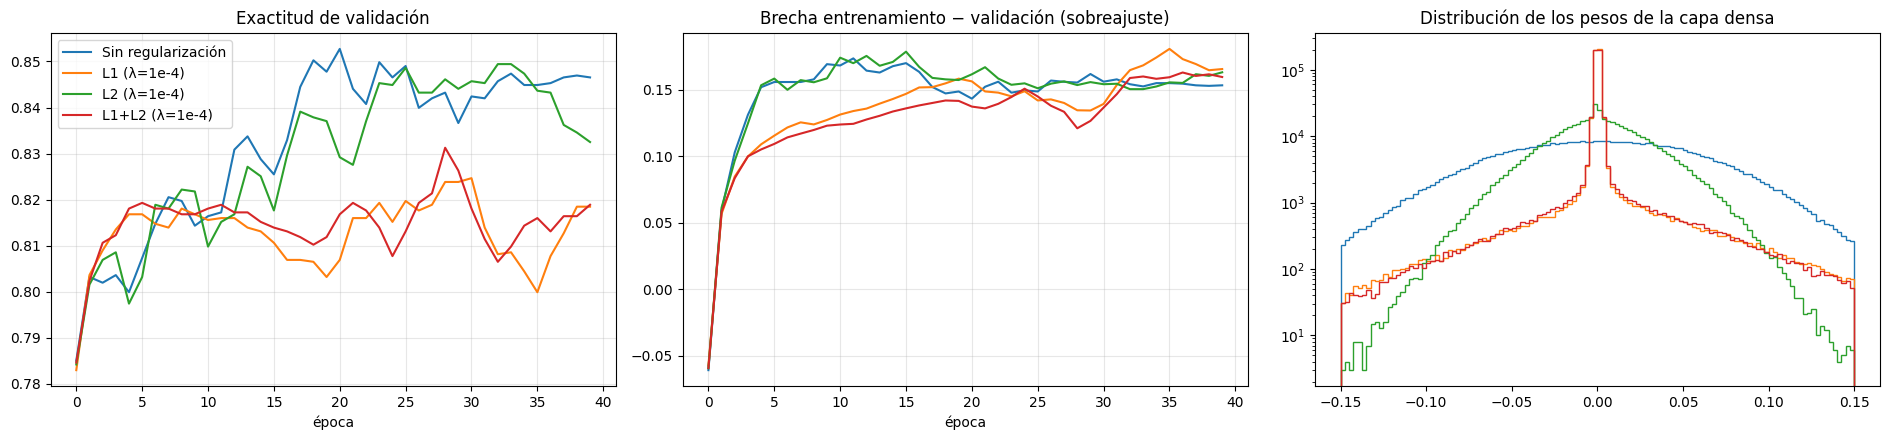

In [17]:
# 8.2 Mismo clasificador con 4 tipos de regularización
EXPERIMENTOS = [("Sin regularización", None), ("L1 (λ=1e-4)", regularizers.L1(1e-4)),
                ("L2 (λ=1e-4)", regularizers.L2(1e-4)), ("L1+L2 (λ=1e-4)", regularizers.L1L2(l1=1e-4, l2=1e-4))]
Ytr1, Yva1 = keras.utils.to_categorical(Y["train"], N_CLASES), keras.utils.to_categorical(Y["val"], N_CLASES)
RES_REG, HIST_REG, PESOS_REG = [], {}, {}
for nombre, reg in EXPERIMENTOS:
    keras.utils.set_random_seed(SEED)
    m = keras.Sequential([keras.Input((FEAT["train"].shape[1],)),
                          layers.Dense(512, activation="relu", kernel_regularizer=reg, name="densa"),
                          layers.Dense(N_CLASES, kernel_regularizer=reg, name="salida")])
    m.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss=keras.losses.CategoricalCrossentropy(from_logits=True), metrics=["accuracy"])
    h = m.fit(FEAT["train"], Ytr1, validation_data=(FEAT["val"], Yva1), epochs=40, batch_size=256, verbose=0)
    hh = pd.DataFrame(h.history); HIST_REG[nombre] = hh
    w = m.get_layer("densa").get_weights()[0]; PESOS_REG[nombre] = w.ravel()
    RES_REG.append({"regularización": nombre, "mejor val_accuracy": hh["val_accuracy"].max(),
                    "train_acc final": hh["accuracy"].iloc[-1], "val_acc final": hh["val_accuracy"].iloc[-1],
                    "brecha train-val": hh["accuracy"].iloc[-1] - hh["val_accuracy"].iloc[-1],
                    "pesos ≈ 0 (|w|<1e-3)": float((np.abs(w) < 1e-3).mean()), "norma L2 pesos": float(np.sqrt((w ** 2).sum()))})
    log.info(f"   {nombre:<20s} mejor val {hh['val_accuracy'].max():.4f} | brecha {RES_REG[-1]['brecha train-val']:+.4f} | "
             f"pesos≈0 {RES_REG[-1]['pesos ≈ 0 (|w|<1e-3)']:.1%}")
TABLA_REG = pd.DataFrame(RES_REG).round(4)
display(TABLA_REG); TABLA_REG.to_csv(EVI / "regularizacion_L1_L2.csv", index=False, encoding="utf-8-sig")

fig, axs = plt.subplots(1, 3, figsize=(19, 4.5))
for nombre, hh in HIST_REG.items():
    axs[0].plot(hh["val_accuracy"], label=nombre)
    axs[1].plot(hh["accuracy"] - hh["val_accuracy"], label=nombre)
    axs[2].hist(PESOS_REG[nombre], bins=120, range=(-0.15, 0.15), histtype="step", lw=1.5, label=nombre)
axs[0].set_title("Exactitud de validación"); axs[1].set_title("Brecha entrenamiento − validación (sobreajuste)")
axs[2].set_title("Distribución de los pesos de la capa densa"); axs[2].set_yscale("log")
for ax in axs[:2]:
    ax.set_xlabel("época"); ax.grid(alpha=0.3)
axs[0].legend(); plt.tight_layout(); plt.savefig(EVI / "regularizacion_L1_L2.png", dpi=110); plt.show()

---
# 9. Destilación de conocimiento: profesor (ensamble EfficientNetV2-S) → estudiante (MobileNetV3-Large)
El estudiante aprende con una pérdida combinada:

**pérdida = α · CE(etiqueta real, estudiante) + (1 − α) · T² · KL( softmax(profesor/T) ‖ softmax(estudiante/T) )**

- **T (temperatura) = 4:** "suaviza" las probabilidades del profesor para que el estudiante aprenda también *cuánto se parecen* las especies (p. ej. que un ñeque negro se parece a un ñeque y no a un jaguar).
- **α = 0,3:** 30 % etiqueta real, 70 % conocimiento del profesor.
- Mismas defensas anti-overfitting: Data Augmentation (con escala de grises), Dropout 0,3, L2, EarlyStopping (activo desde la época 50), ReduceLROnPlateau. **60 épocas**.

In [18]:
# 9.1 Modelo estudiante: MobileNetV3-Large (ImageNet) + cabeza
T_KD, ALPHA_KD = 4.0, 0.3
EPOCAS_EST_1, EPOCAS_EST_TOTAL, EPOCA_MIN_EST = 5, 60, 50

keras.utils.set_random_seed(SEED)
base_est = keras.applications.MobileNetV3Large(input_shape=(IMG_EST, IMG_EST, 3), include_top=False,
                                              weights="imagenet", pooling="avg")
base_est.trainable = False
ent = keras.Input((IMG_EST, IMG_EST, 3), name="imagen")
x = base_est(ent, training=False)
x = layers.Dropout(0.3, name="dropout")(x)
salida_logits = layers.Dense(N_CLASES, kernel_regularizer=regularizers.L2(1e-4), name="logits")(x)
NUCLEO = keras.Model(ent, salida_logits, name="estudiante_mobilenetv3")      # lo que irá al celular
ent2 = keras.Input((IMG_EST, IMG_EST, 3), name="imagen")
ESTUDIANTE = keras.Model(ent2, NUCLEO(crear_aumento()(ent2)), name="estudiante_con_aumento")

def perdida_destilacion(y, logits):
    y_dura, z_prof = y[:, :N_CLASES], y[:, N_CLASES:]
    logits = tf.cast(logits, tf.float32)
    dura = keras.losses.categorical_crossentropy(y_dura, logits, from_logits=True)
    p_prof = tf.nn.softmax(z_prof / T_KD)
    suave = tf.reduce_sum(p_prof * (tf.math.log(p_prof + 1e-8) - tf.nn.log_softmax(logits / T_KD)), axis=-1) * T_KD ** 2
    return ALPHA_KD * dura + (1 - ALPHA_KD) * suave

def accuracy(y, logits):
    return keras.metrics.categorical_accuracy(y[:, :N_CLASES], logits)
def top3(y, logits):
    return keras.metrics.top_k_categorical_accuracy(y[:, :N_CLASES], logits, k=3)

def compilar_est(lr):
    ESTUDIANTE.compile(optimizer=keras.optimizers.Adam(lr), loss=perdida_destilacion, metrics=[accuracy, top3])

compilar_est(1e-3)
log.info(f"ESTUDIANTE MobileNetV3-Large: {NUCLEO.count_params():,} parámetros "
         f"(profesor: {sum(m.count_params() for m in MODELOS.values()):,}) | T={T_KD} α={ALPHA_KD}")

2026-10-24 00:02:23 | INFO    | ESTUDIANTE MobileNetV3-Large: 3,034,792 parámetros (profesor: 42,015,504) | T=4.0 α=0.3


In [19]:
# 9.2 Datos: imagen 224 px + objetivo = [etiqueta real (40) | logits del profesor (40)]
def ds_destilacion(df, grupo, entrenamiento=False):
    objetivo = np.concatenate([keras.utils.to_categorical(df["y"].values, N_CLASES), LOG_PROF[grupo]], axis=1).astype("float32")
    if entrenamiento:
        ds = tf.data.Dataset.from_tensor_slices((df["ruta"].values, objetivo, df["peso"].values.astype("float32")))
        ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)
        ds = ds.map(lambda r, o, w: (leer_imagen(r, IMG_EST), o, w), num_parallel_calls=AUTOTUNE)
    else:
        ds = tf.data.Dataset.from_tensor_slices((df["ruta"].values, objetivo))
        ds = ds.map(lambda r, o: (leer_imagen(r, IMG_EST), o), num_parallel_calls=AUTOTUNE)
    return ds.batch(64).prefetch(AUTOTUNE)

dsd_train, dsd_val = ds_destilacion(TRAIN, "train", True), ds_destilacion(VAL, "val")
if PRUEBA_RAPIDA:
    dsd_train, dsd_val = dsd_train.take(10), dsd_val.take(3)

F_MEJOR_EST = SALIDA / "estudiante_mejor.weights.h5"
def callbacks_est(etapa):
    return [keras.callbacks.ModelCheckpoint(str(F_MEJOR_EST), monitor="val_accuracy", mode="max",
                                            save_best_only=True, save_weights_only=True),
            keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=12, min_delta=0,
                                          start_from_epoch=EPOCA_MIN_EST, restore_best_weights=True, verbose=1),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=4, min_lr=1e-7, verbose=1),
            keras.callbacks.CSVLogger(str(SALIDA / f"historial_estudiante_{etapa}.csv")),
            RegistroLogEst(etapa)]

class RegistroLogEst(keras.callbacks.Callback):
    def __init__(self, etapa):
        super().__init__(); self.etapa = etapa
    def on_epoch_begin(self, epoch, logs=None):
        self.t = time.time()
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        log.info(f"[estudiante {self.etapa}] época {epoch + 1:02d}/{EPOCAS_EST_TOTAL} | " +
                 " | ".join(f"{k}={float(v):.4f}" for k, v in logs.items()) + f" | {time.time() - self.t:.0f} s")
print("Datos de destilación listos")

Datos de destilación listos


In [20]:
# 9.3 ENTRENAMIENTO del estudiante: etapa 1 (base congelada) + etapa 2 (fine-tuning de toda la red, BatchNorm congelada)
log.info("=" * 70)
log.info(f"DESTILACIÓN etapa 1: {EPOCAS_EST_1} épocas, base congelada, Adam 1e-3")
h1 = ESTUDIANTE.fit(dsd_train, validation_data=dsd_val, epochs=1 if PRUEBA_RAPIDA else EPOCAS_EST_1,
                    callbacks=callbacks_est("etapa1"), verbose=0)
hechas = len(h1.epoch)

base_est.trainable = True
for capa in base_est.layers:
    if isinstance(capa, layers.BatchNormalization):
        capa.trainable = False
compilar_est(1e-4)
fin = hechas + 1 if PRUEBA_RAPIDA else EPOCAS_EST_TOTAL
log.info(f"DESTILACIÓN etapa 2: fine-tuning de MobileNetV3 | Adam 1e-4 | épocas {hechas + 1} a {fin}")
t0 = time.time()
h2 = ESTUDIANTE.fit(dsd_train, validation_data=dsd_val, epochs=fin, initial_epoch=hechas,
                    callbacks=callbacks_est("etapa2"), verbose=0)
ESTUDIANTE.load_weights(F_MEJOR_EST)
log.info(f"Destilación terminada: {hechas + len(h2.epoch)} épocas en total ({(time.time() - t0) / 60:.0f} min la etapa 2)")

2026-10-24 00:02:23 | INFO    | ======================================================================
2026-10-24 00:02:23 | INFO    | DESTILACIÓN etapa 1: 5 épocas, base congelada, Adam 1e-3
2026-10-24 00:03:05 | INFO    | [estudiante etapa1] época 01/60 | accuracy=0.4557 | loss=1.5572 | top3=0.6545 | val_accuracy=0.7772 | val_loss=0.7710 | val_top3=0.9183 | learning_rate=0.0010 | 42 s
2026-10-24 00:03:36 | INFO    | [estudiante etapa1] época 02/60 | accuracy=0.6532 | loss=1.1210 | top3=0.8300 | val_accuracy=0.8036 | val_loss=0.6730 | val_top3=0.9311 | learning_rate=0.0010 | 31 s
2026-10-24 00:04:17 | INFO    | [estudiante etapa1] época 03/60 | accuracy=0.6831 | loss=1.0279 | top3=0.8506 | val_accuracy=0.7999 | val_loss=0.6666 | val_top3=0.9328 | learning_rate=0.0010 | 41 s
2026-10-24 00:04:48 | INFO    | [estudiante etapa1] época 04/60 | accuracy=0.7016 | loss=0.9864 | top3=0.8602 | val_accuracy=0.8036 | val_loss=0.6428 | val_top3=0.9319 | learning_rate=0.0010 | 31 s
2026-10-24 00:05

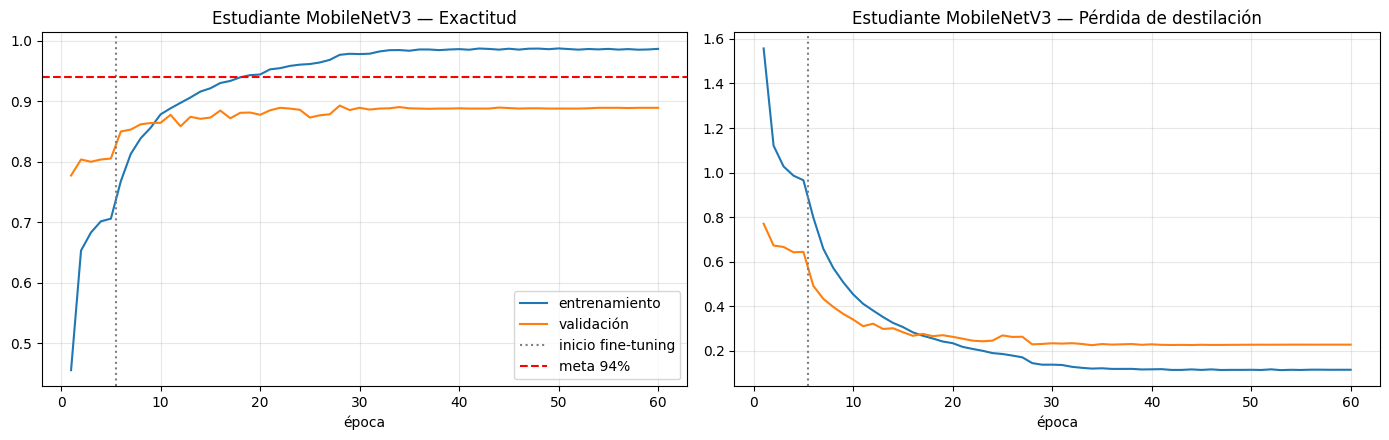

2026-10-24 01:10:16 | INFO    | Estudiante — mejor época 28 | val_accuracy 0.8927 | épocas ejecutadas 60


In [21]:
# 9.4 Curvas del estudiante
hist_est = pd.concat([pd.read_csv(SALIDA / f"historial_estudiante_etapa{k}.csv") for k in (1, 2)])
hist_est = hist_est.drop_duplicates("epoch", keep="last").sort_values("epoch").reset_index(drop=True)
hist_est["epoca"] = hist_est["epoch"] + 1
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (m, tit) in zip(axs, [("accuracy", "Exactitud"), ("loss", "Pérdida de destilación")]):
    ax.plot(hist_est["epoca"], hist_est[m], label="entrenamiento"); ax.plot(hist_est["epoca"], hist_est[f"val_{m}"], label="validación")
    ax.axvline(EPOCAS_EST_1 + 0.5, ls=":", c="gray", label="inicio fine-tuning"); ax.set_title(f"Estudiante MobileNetV3 — {tit}")
    ax.set_xlabel("época"); ax.grid(alpha=0.3)
axs[0].axhline(META_ACCURACY, ls="--", c="red", label=f"meta {META_ACCURACY:.0%}"); axs[0].legend()
plt.tight_layout(); plt.savefig(EVI / "estudiante_curvas.png", dpi=110); plt.show()
mejor_est = hist_est.loc[hist_est["val_accuracy"].idxmax()]
log.info(f"Estudiante — mejor época {int(mejor_est['epoca'])} | val_accuracy {mejor_est['val_accuracy']:.4f} | "
         f"épocas ejecutadas {int(hist_est['epoca'].max())}")

In [22]:
# 9.5 Evaluación del estudiante (solo imagen y con ubicación; TTA y peso de la ubicación elegidos con VALIDACIÓN)
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import unicodedata

def logits_est(df, volteo=False):
    ds = hacer_ds(df, size=IMG_EST)
    if volteo:
        ds = ds.map(lambda x, y: (tf.image.flip_left_right(x), y))
    return NUCLEO.predict(ds, verbose=0)
L_EST = {g: (logits_est(df), logits_est(df, True)) for g, df in [("val", VAL), ("test", TEST)]}
soft = lambda z: tf.nn.softmax(z).numpy()
def prob_est(g, tta):
    a, b = L_EST[g]
    return (soft(a) + soft(b)) / 2 if tta else soft(a)
TTA_EST = acc_np(prob_est("val", True), "val") > acc_np(prob_est("val", False), "val")

def norm_dep(s):
    def f(x):
        if not isinstance(x, str) or not x.strip():
            return "desconocido"
        x = "".join(c for c in unicodedata.normalize("NFD", x.lower()) if unicodedata.category(c) != "Mn")
        for q in ["departamento de ", "departamento del ", "depto. de ", "depto ", "departamento "]:
            x = x.replace(q, "")
        return x.strip()
    return s.map(f)
DEP = {"train": norm_dep(TRAIN["departamento"]), "val": norm_dep(VAL["departamento"]), "test": norm_dep(TEST["departamento"])}
CONTEO = pd.crosstab(DEP["train"], TRAIN["y"]).reindex(columns=range(N_CLASES), fill_value=0).drop(index="desconocido", errors="ignore")
def tabla_factor(alpha):
    p_dep = (CONTEO + alpha).div(CONTEO.sum(1) + alpha * N_CLASES, axis=0)
    glob = CONTEO.sum(0) + alpha
    return p_dep / (glob / glob.sum())
def con_lugar(p, deps, alpha, lam):
    r = tabla_factor(alpha)
    f = np.vstack([r.loc[d].values if d in r.index else np.ones(N_CLASES) for d in deps])
    q = p * f ** lam
    return q / q.sum(1, keepdims=True)

grid = sorted(((acc_np(con_lugar(prob_est("val", TTA_EST), DEP["val"], a, l), "val"), -l, a, l)
               for a in [1, 3, 10] for l in [0, 0.25, 0.5, 0.75, 1.0]), reverse=True)
_, _, A_EST, L_EST_LUG = grid[0]

def metricas(p, g):
    yp = p.argmax(1); yt = Y[g]
    _, _, f1, _ = precision_recall_fscore_support(yt, yp, labels=range(N_CLASES), average="macro", zero_division=0)
    return {"accuracy": accuracy_score(yt, yp), "top3": float(np.mean([t in np.argsort(q)[-3:] for t, q in zip(yt, p)])), "f1_macro": f1}

P_EST_IMG = {g: prob_est(g, TTA_EST) for g in ("val", "test")}
P_EST_LUG = {g: con_lugar(P_EST_IMG[g], DEP[g], A_EST, L_EST_LUG) for g in ("val", "test")}
P_PROF = {g: combinar(PESOS_ENS, g, TTA_ENS) for g in ("val", "test")}       # exactamente el ensamble de la sección 7
P_PROF_LUG = {g: con_lugar(P_PROF[g], DEP[g], A_LUG, L_LUG) for g in ("val", "test")}   # α y λ de la sección 7.6
COMP = pd.DataFrame([
    {"modelo": "Profesor: ensamble 2× EfficientNetV2-S (solo imagen)", **{f"val_{k}": v for k, v in metricas(P_PROF['val'], 'val').items()}, **{f"test_{k}": v for k, v in metricas(P_PROF['test'], 'test').items()}},
    {"modelo": "Profesor + ubicación", **{f"val_{k}": v for k, v in metricas(P_PROF_LUG['val'], 'val').items()}, **{f"test_{k}": v for k, v in metricas(P_PROF_LUG['test'], 'test').items()}},
    {"modelo": "Estudiante MobileNetV3 destilado (solo imagen)", **{f"val_{k}": v for k, v in metricas(P_EST_IMG['val'], 'val').items()}, **{f"test_{k}": v for k, v in metricas(P_EST_IMG['test'], 'test').items()}},
    {"modelo": "Estudiante + ubicación", **{f"val_{k}": v for k, v in metricas(P_EST_LUG['val'], 'val').items()}, **{f"test_{k}": v for k, v in metricas(P_EST_LUG['test'], 'test').items()}},
]).round(4)
display(COMP[["modelo", "val_accuracy", "test_accuracy", "test_top3", "test_f1_macro"]])
COMP.to_csv(EVI / "profesor_vs_estudiante.csv", index=False, encoding="utf-8-sig")
log.info(f"Estudiante: TTA={'sí' if TTA_EST else 'no'} | ubicación alpha={A_EST} lambda={L_EST_LUG} (elegidos con validación)")
for _, r in COMP.iterrows():
    log.info(f"   {r['modelo']:<52s} val {r['val_accuracy']:.4f} | prueba {r['test_accuracy']:.4f} | top-3 {r['test_top3']:.4f} | F1 {r['test_f1_macro']:.4f}")

2026-10-24 01:10:43.933705: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 01:10:44.069567: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 01:10:44.399684: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 01:10:44.537605: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


,modelo,val_accuracy,test_accuracy,test_top3,test_f1_macro
0,Profesor: ensamble 2× EfficientNetV2-S (solo i...,0.9278,0.9373,0.9849,0.9200
1,Profesor + ubicación,0.9530,0.9536,0.9882,0.9413
2,Estudiante MobileNetV3 destilado (solo imagen),0.8936,0.9076,0.9768,0.8764
3,Estudiante + ubicación,0.9220,0.9353,0.9784,0.9191


2026-10-24 01:10:52 | INFO    | Estudiante: TTA=sí | ubicación alpha=1 lambda=1.0 (elegidos con validación)
2026-10-24 01:10:52 | INFO    |    Profesor: ensamble 2× EfficientNetV2-S (solo imagen) val 0.9278 | prueba 0.9373 | top-3 0.9849 | F1 0.9200
2026-10-24 01:10:52 | INFO    |    Profesor + ubicación                                 val 0.9530 | prueba 0.9536 | top-3 0.9882 | F1 0.9413
2026-10-24 01:10:52 | INFO    |    Estudiante MobileNetV3 destilado (solo imagen)       val 0.8936 | prueba 0.9076 | top-3 0.9768 | F1 0.8764
2026-10-24 01:10:52 | INFO    |    Estudiante + ubicación                               val 0.9220 | prueba 0.9353 | top-3 0.9784 | F1 0.9191


---
# 10. Preparación para el celular: TensorFlow Lite (tamaño, latencia y exactitud)

In [23]:
# 10.1 Exportar el estudiante (imagen 224 px RGB 0..255 → probabilidades) y convertir a TFLite
FINAL = keras.Model(NUCLEO.input, layers.Softmax(name="probabilidades")(NUCLEO.output), name="mamiferos_colombia_movil")
FINAL.save(SALIDA / "estudiante_mobilenetv3.keras")
DIR_SM = SALIDA / "estudiante_savedmodel"
FINAL.export(str(DIR_SM))

TFLITE = {}
def convertir(nombre, configurar):
    try:
        conv = tf.lite.TFLiteConverter.from_saved_model(str(DIR_SM))
        configurar(conv)
        datos = conv.convert()
        ruta = SALIDA / f"mamiferos_{nombre}.tflite"; ruta.write_bytes(datos)
        TFLITE[nombre] = ruta
        log.info(f"TFLite {nombre}: {len(datos) / 1e6:.1f} MB")
    except Exception as e:
        log.info(f"TFLite {nombre}: no se pudo convertir ({type(e).__name__}: {str(e)[:150]})")

def _fp16(c):
    c.optimizations = [tf.lite.Optimize.DEFAULT]; c.target_spec.supported_types = [tf.float16]
def _int8(c):
    c.optimizations = [tf.lite.Optimize.DEFAULT]
convertir("float32", lambda c: None)
convertir("float16", _fp16)
convertir("int8_dinamico", _int8)

INFO:tensorflow:Assets written to: /kaggle/working/ensamble/estudiante_savedmodel/assets


INFO:tensorflow:Assets written to: /kaggle/working/ensamble/estudiante_savedmodel/assets


Saved artifact at '/kaggle/working/ensamble/estudiante_savedmodel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='imagen')
Output Type:
  TensorSpec(shape=(None, 40), dtype=tf.float32, name=None)
Captures:
  132629456806224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132628542935056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132628542934672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132629456804880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132628542934864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132628541946384: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132628541944272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132628541944080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132628541945616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132628541946192: TensorSpec(shape=(), dtype=tf.resource, na

W0000 00:00:1792804263.144862      24 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1792804263.144909      24 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1792804263.282925      24 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
W0000 00:00:1792804269.353219      24 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1792804269.353251      24 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.


2026-10-24 01:11:11 | INFO    | TFLite float16: 6.1 MB
2026-10-24 01:11:18 | INFO    | TFLite int8_dinamico: 3.3 MB


W0000 00:00:1792804275.408437      24 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1792804275.408479      24 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.


In [24]:
# 10.2 Medir exactitud y latencia de cada versión TFLite (CPU, 1 imagen a la vez, como en un celular)
def evaluar_tflite(ruta, df, n_lat=100):
    it = tf.lite.Interpreter(model_path=str(ruta), num_threads=4); it.allocate_tensors()
    ent_d, sal_d = it.get_input_details()[0], it.get_output_details()[0]
    probs, tiempos = [], []
    for i, r in enumerate(df["ruta"]):
        x = leer_imagen(r, IMG_EST).numpy()[None].astype(ent_d["dtype"])
        t0 = time.perf_counter(); it.set_tensor(ent_d["index"], x); it.invoke()
        if i < n_lat:
            tiempos.append((time.perf_counter() - t0) * 1000)
        probs.append(it.get_tensor(sal_d["index"])[0])
    return np.array(probs), float(np.median(tiempos))

FILAS_MOVIL = []
for nombre, ruta in TFLITE.items():
    p, ms = evaluar_tflite(ruta, TEST.iloc[:300] if PRUEBA_RAPIDA else TEST)
    g = "test"; yt = Y[g][:len(p)]
    p_l = con_lugar(p, DEP[g].iloc[:len(p)], A_EST, L_EST_LUG)
    FILAS_MOVIL.append({"versión": f"TFLite {nombre}", "tamaño_MB": round(ruta.stat().st_size / 1e6, 1), "latencia_ms": round(ms, 1),
                        "test_accuracy": round(float((p.argmax(1) == yt).mean()), 4),
                        "test_accuracy_con_ubicacion": round(float((p_l.argmax(1) == yt).mean()), 4)})
    log.info(f"   {FILAS_MOVIL[-1]}")
display(pd.DataFrame(FILAS_MOVIL))

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


2026-10-24 01:11:41 | INFO    |    {'versión': 'TFLite float32', 'tamaño_MB': 12.0, 'latencia_ms': 3.6, 'test_accuracy': 0.9048, 'test_accuracy_con_ubicacion': 0.9365}
2026-10-24 01:12:05 | INFO    |    {'versión': 'TFLite float16', 'tamaño_MB': 6.1, 'latencia_ms': 3.7, 'test_accuracy': 0.9036, 'test_accuracy_con_ubicacion': 0.9369}
2026-10-24 01:13:03 | INFO    |    {'versión': 'TFLite int8_dinamico', 'tamaño_MB': 3.3, 'latencia_ms': 15.5, 'test_accuracy': 0.902, 'test_accuracy_con_ubicacion': 0.9308}


,versión,tamaño_MB,latencia_ms,test_accuracy,test_accuracy_con_ubicacion
0,TFLite float32,12.0,3.6,0.9048,0.9365
1,TFLite float16,6.1,3.7,0.9036,0.9369
2,TFLite int8_dinamico,3.3,15.5,0.9020,0.9308


---
# 11. Ensamble (profesor) vs. modelo destilado (estudiante) + archivos para la app

,modelo,parámetros,tamaño_MB,latencia_CPU_ms,test_acc_imagen,test_acc_con_ubicacion
0,Profesor: ensamble 2× EfficientNetV2-S,42015504,630.5,2357.8,0.9373,0.9536
1,Estudiante MobileNetV3 (Keras),3034792,12.8,246.3,0.9076,0.9353
2,TFLite float32,3034792,12.0,3.6,0.9048,0.9365
3,TFLite float16,3034792,6.1,3.7,0.9036,0.9369
4,TFLite int8_dinamico,3034792,3.3,15.5,0.9020,0.9308


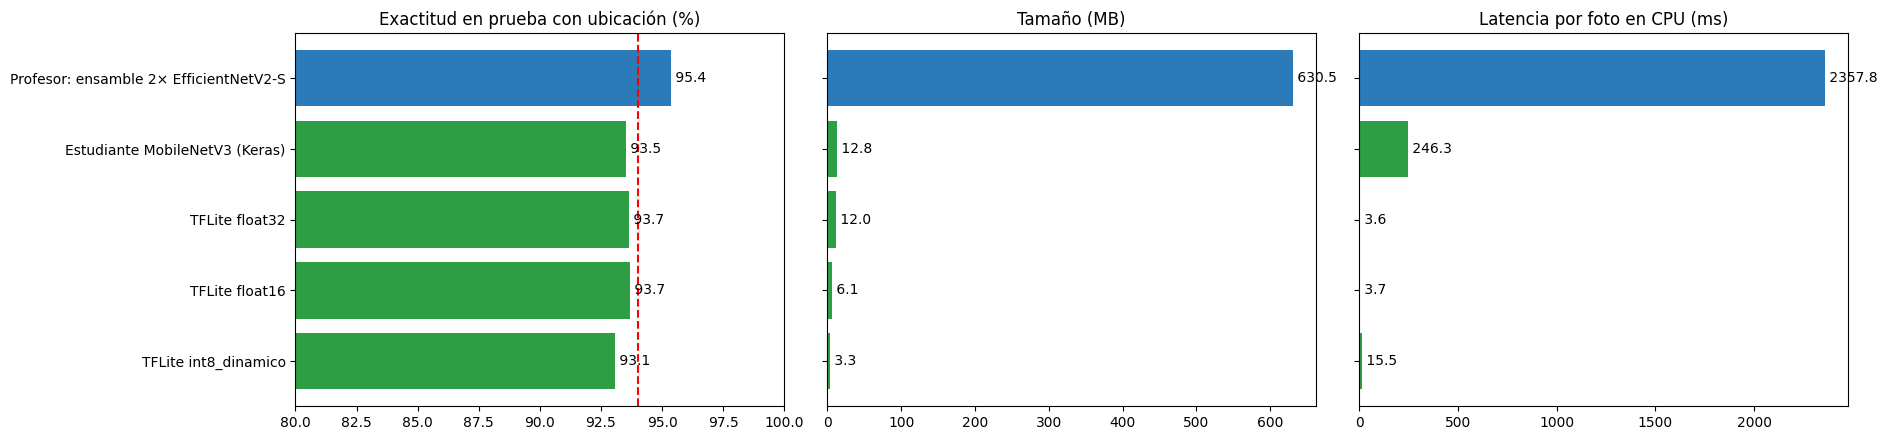

2026-10-24 01:14:23 | INFO    | ENSAMBLE vs DESTILADO:
                                modelo  parámetros  tamaño_MB  latencia_CPU_ms  test_acc_imagen  test_acc_con_ubicacion
Profesor: ensamble 2× EfficientNetV2-S    42015504      630.5           2357.8           0.9373                  0.9536
        Estudiante MobileNetV3 (Keras)     3034792       12.8            246.3           0.9076                  0.9353
                        TFLite float32     3034792       12.0              3.6           0.9048                  0.9365
                        TFLite float16     3034792        6.1              3.7           0.9036                  0.9369
                  TFLite int8_dinamico     3034792        3.3             15.5           0.9020                  0.9308


In [25]:
# 11.1 Tabla final: exactitud, tamaño y velocidad
def latencia_keras(modelos, df, n=30, size=IMG_SIZE):
    ts = []
    with tf.device("/CPU:0"):
        for r in df["ruta"].iloc[:n]:
            x = leer_imagen(r, size)[None]
            t0 = time.perf_counter()
            for m in modelos:
                m(x, training=False)
            ts.append((time.perf_counter() - t0) * 1000)
    return float(np.median(ts[3:]))

tam_prof = sum(r.stat().st_size for r in RUTAS_MODELOS) / 1e6
lat_prof = latencia_keras(list(MODELOS.values()), TEST)
lat_est = latencia_keras([NUCLEO], TEST, size=IMG_EST)
fila = lambda nombre, i: COMP.iloc[i]
FINAL_TABLA = pd.DataFrame([
    {"modelo": "Profesor: ensamble 2× EfficientNetV2-S", "parámetros": sum(m.count_params() for m in MODELOS.values()),
     "tamaño_MB": round(tam_prof, 1), "latencia_CPU_ms": round(lat_prof, 1),
     "test_acc_imagen": COMP.iloc[0]["test_accuracy"], "test_acc_con_ubicacion": COMP.iloc[1]["test_accuracy"]},
    {"modelo": "Estudiante MobileNetV3 (Keras)", "parámetros": NUCLEO.count_params(),
     "tamaño_MB": round((SALIDA / "estudiante_mobilenetv3.keras").stat().st_size / 1e6, 1), "latencia_CPU_ms": round(lat_est, 1),
     "test_acc_imagen": COMP.iloc[2]["test_accuracy"], "test_acc_con_ubicacion": COMP.iloc[3]["test_accuracy"]},
] + [{"modelo": f["versión"], "parámetros": NUCLEO.count_params(), "tamaño_MB": f["tamaño_MB"], "latencia_CPU_ms": f["latencia_ms"],
      "test_acc_imagen": f["test_accuracy"], "test_acc_con_ubicacion": f["test_accuracy_con_ubicacion"]} for f in FILAS_MOVIL])
display(FINAL_TABLA); FINAL_TABLA.to_csv(EVI / "ensamble_vs_destilado.csv", index=False, encoding="utf-8-sig")

fig, axs = plt.subplots(1, 3, figsize=(19, 4.5))
cols = ["#2b7bba"] + ["#2e9e44"] * (len(FINAL_TABLA) - 1)
for ax, (c, tit) in zip(axs, [("test_acc_con_ubicacion", "Exactitud en prueba con ubicación (%)"), ("tamaño_MB", "Tamaño (MB)"),
                              ("latencia_CPU_ms", "Latencia por foto en CPU (ms)")]):
    v = FINAL_TABLA[c] * (100 if "acc" in c else 1)
    ax.barh(FINAL_TABLA["modelo"], v, color=cols); ax.set_title(tit); ax.invert_yaxis()
    for i, val in enumerate(v):
        ax.text(val, i, f" {val:.1f}", va="center")
axs[0].axvline(META_ACCURACY * 100, ls="--", c="red"); axs[0].set_xlim(80, 100)
for ax in axs[1:]:
    ax.set_yticklabels([])
plt.tight_layout(); plt.savefig(EVI / "ensamble_vs_destilado.png", dpi=110); plt.show()
log.info("ENSAMBLE vs DESTILADO:\n" + FINAL_TABLA.to_string(index=False))

In [26]:
# 11.2 Archivos para la aplicación móvil: modelo .tflite + etiquetas + tabla de ubicación por departamento
APP = SALIDA / "app"; APP.mkdir(exist_ok=True)
mejor_tfl = "float16" if "float16" in TFLITE else (next(iter(TFLITE)) if TFLITE else None)
if mejor_tfl:
    shutil.copy(TFLITE[mejor_tfl], APP / "mamiferos.tflite")
json.dump({"clases": CLASES, "nombres": [NOMBRE[c] for c in CLASES], "img_size": IMG_EST,
           "entrada": "RGB 0..255, 224x224 (el modelo normaliza por dentro)", "salida": "probabilidades de 40 especies"},
          open(APP / "etiquetas.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
fac = tabla_factor(A_EST)
json.dump({"alpha": float(A_EST), "lambda": float(L_EST_LUG),
           "uso": "p_final ∝ p_modelo × factor[departamento] ^ lambda ; si el departamento no está, factor = 1",
           "factor_por_departamento": {d: [round(float(v), 4) for v in fac.loc[d].values] for d in fac.index}},
          open(APP / "ubicacion_departamentos.json", "w", encoding="utf-8"), ensure_ascii=False)
resumen = {"fecha": datetime.now().isoformat(timespec="seconds"), "profesor": list(MODELOS), "pesos_ensamble": list(PESOS_ENS), "estudiante": "MobileNetV3-Large 224px",
           "T": T_KD, "alpha": ALPHA_KD, "epocas_estudiante": int(hist_est["epoca"].max()), "mejor_epoca": int(mejor_est["epoca"]),
           "comparacion": COMP.to_dict("records"), "movil": FILAS_MOVIL, "regularizacion": TABLA_REG.to_dict("records")}
json.dump(resumen, open(EVI / "resumen_destilacion.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1, default=float)
log.info(f"Archivos para la app en {APP}: {[p.name for p in APP.iterdir()]}")

2026-10-24 01:14:23 | INFO    | Archivos para la app en /kaggle/working/ensamble/app: ['ubicacion_departamentos.json', 'etiquetas.json', 'mamiferos.tflite']
